# 02 Dirtiness profile (D1–D7)

Per-column heuristics, aggregated per table. Every number here has to be defensible in the
report, so nothing is a learned score.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import pandas as pd
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

In [2]:
from swsn.profile import profile_table, table_summary, dimension_flags, DIMENSION_FLAGS

print("dimension definitions")
for dim, rule in DIMENSION_FLAGS.items():
    print(f"  {dim}: {rule}")

dimension definitions
  D1: share_flagged_names > 0
  D2: share_mixed_type > 0
  D3: max_missing_rate > 0.01 or max_sentinel_rate > 0.005
  D4: share_typed_with_variants > 0
  D5: share_variant_categorical > 0
  D6: share_freetext > 0 or n_constant_columns > 0
  D7: max_abs_skew > 2 or mean_zero_inflation > 0.5 or max_outlier_rate > 0.05


In [3]:
from swsn.schema_doc import load_all_schemas
from swsn.tables import load_tables

schemas = load_all_schemas("../ground_truth/schema")
summaries = []
for did, schema in schemas.items():
    tables = load_tables(did, list(schema["tables"]), data_dir="../data", nrows=50_000)
    for name, df in tables.items():
        summary = table_summary(profile_table(df))
        flags = dimension_flags(summary)
        summaries.append({"dataset": did, "table": name,
                          **{k: int(v) for k, v in flags.items()},
                          "n": sum(flags.values())})
pd.DataFrame(summaries).sort_values("n", ascending=False)

,dataset,table,D1,D2,D3,D4,D5,D6,D7,n
11,olist,olist_order_reviews_dataset,0,0,1,0,1,0,1,3
0,instacart,orders,0,0,1,0,0,0,1,2
12,olist,olist_products_dataset,0,0,1,0,0,0,1,2
3,instacart,products,0,0,0,0,0,1,0,1
8,olist,olist_orders_dataset,0,0,1,0,0,0,0,1
9,olist,olist_order_items_dataset,0,0,0,0,0,0,1,1
10,olist,olist_order_payments_dataset,0,0,0,0,0,0,1,1
1,instacart,order_products__prior,0,0,0,0,0,0,0,0
2,instacart,order_products__train,0,0,0,0,0,0,0,0
4,instacart,aisles,0,0,0,0,0,0,0,0


## The dimension-by-table matrix

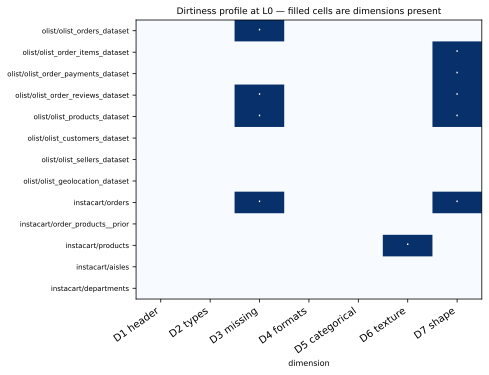

In [4]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
from IPython.display import SVG, display
display(SVG(filename="../reports/figures/f1_dirtiness.svg"))

## Reading the matrix

- **D1, D2 and D4 are empty everywhere.** Both datasets have clean snake_case headers,
  stable inferred types and one format per column. Whatever "messy Kaggle data" means, it
  is not this, at L0.
- **D3 is structural where it appears.** Instacart's `days_since_prior_order` is null for
  every user's first order — 206k of 3.4M rows. That is the definition of the column, not
  missing data.
- **D7 fires on money and counts.** Prices, payment values and weights are all strongly
  right-skewed; that is what `DistributionBased` sees and what makes it behave differently
  from the string matchers.

The mess this project is about is therefore mostly *cross-table* — the same concept written
differently on each side — which is exactly what the strata and the D8 quadrants measure,
and exactly what the L1–L4 operators introduce.